# ORBITALROUTE AI
## Notebook de análisis de datos y Machine Learning

**Tema:** Predicción de calidad de servicio (QoS) e inferencia bayesiana en enlaces intersatelitales LEO.

**Propósito:** documentar un flujo reproducible de generación/carga de datos, limpieza, análisis exploratorio, preparación temporal, regresión bayesiana y evaluación.

> **Alcance académico:** el reporte del proyecto indica que aún no existe un conjunto experimental consolidado ni modelos entrenados con datos reales. Por ello, este notebook incorpora un conjunto **sintético y demostrativo** para que el flujo pueda ejecutarse y revisarse. Sus resultados no deben presentarse como mediciones reales ni como evidencia de desempeño de OrbitalRoute AI.

### Variables incluidas
- `timestamp`: instante de observación.
- `latency_ms`: latencia (variable objetivo).
- `packet_loss_pct`: pérdida de paquetes.
- `availability_pct`: disponibilidad.
- `distance_km`: distancia ilustrativa del enlace.
- `relative_velocity_km_s`: velocidad relativa ilustrativa.


## 1. Importación de bibliotecas

Se utilizan herramientas de Python para manipulación de datos, visualización y modelado. Si alguna biblioteca no está instalada, puede instalarse desde una celda de Jupyter con `!pip install ...`.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import BayesianRidge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)

print("Bibliotecas cargadas correctamente.")


Bibliotecas cargadas correctamente.


## 2. Conjunto de datos

El siguiente bloque genera 240 observaciones sintéticas. Las relaciones entre variables son artificiales y se utilizan exclusivamente para demostrar el procesamiento y el modelado.


In [16]:
rng = np.random.default_rng(SEED)
n = 240

timestamps = pd.date_range(
    start="2026-01-01 00:00:00",
    periods=n,
    freq="5min"
)

distance_km = rng.uniform(500, 5000, n)
relative_velocity_km_s = rng.uniform(0.1, 7.5, n)
packet_loss_pct = rng.uniform(0.0, 3.0, n)
availability_pct = rng.uniform(96.0, 100.0, n)

# Variable objetivo sintética: no son mediciones reales.
latency_ms = (
    12
    + 0.009 * distance_km
    + 1.8 * packet_loss_pct
    - 0.35 * (availability_pct - 96)
    + 0.7 * relative_velocity_km_s
    + rng.normal(0, 3, n)
)

df = pd.DataFrame({
    "timestamp": timestamps,
    "latency_ms": latency_ms,
    "packet_loss_pct": packet_loss_pct,
    "availability_pct": availability_pct,
    "distance_km": distance_km,
    "relative_velocity_km_s": relative_velocity_km_s
})

df.head(10)


,timestamp,latency_ms,packet_loss_pct,availability_pct,distance_km,relative_velocity_km_s
0,2026-01-01 00:00:00,54.942641,1.226349,98.050928,3982.802219,6.237772
1,2026-01-01 00:05:00,38.344314,0.652886,97.731890,2474.952979,5.996446
2,2026-01-01 00:10:00,55.902109,1.764919,96.143371,4363.690640,1.821541
3,2026-01-01 00:15:00,47.949178,0.951123,99.839098,3638.156131,4.027695
4,2026-01-01 00:20:00,24.918836,0.108180,96.412011,923.798065,4.584517
5,2026-01-01 00:25:00,66.275365,1.255200,96.164316,4890.300582,6.521268
6,2026-01-01 00:30:00,57.678258,1.422398,96.984266,3925.128659,4.562993
7,2026-01-01 00:35:00,52.598044,0.676779,96.262122,4037.289374,3.153030
8,2026-01-01 00:40:00,27.919624,1.717374,97.820471,1076.511347,2.868962
9,2026-01-01 00:45:00,35.896752,1.697316,98.064351,2526.736721,3.251527


## 3. Descripción general de los datos

Se revisan las dimensiones, los tipos de datos, los valores faltantes y los estadísticos descriptivos.


In [17]:
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
display(df.dtypes)

print("\nValores faltantes por columna:")
display(df.isna().sum())

print("\nEstadísticos descriptivos:")
display(df.describe().round(3))


Dimensiones: (240, 6)

Tipos de datos:


timestamp                 datetime64[us]
latency_ms                       float64
packet_loss_pct                  float64
availability_pct                 float64
distance_km                      float64
relative_velocity_km_s           float64
dtype: object


Valores faltantes por columna:


timestamp                 0
latency_ms                0
packet_loss_pct           0
availability_pct          0
distance_km               0
relative_velocity_km_s    0
dtype: int64


Estadísticos descriptivos:


,timestamp,latency_ms,packet_loss_pct,availability_pct,distance_km,relative_velocity_km_s
count,240,240.000,240.000,240.000,240.000,240.000
mean,2026-01-01 09:57:30,41.397,1.561,97.904,2718.877,3.803
min,2026-01-01 00:00:00,15.899,0.014,96.005,533.130,0.140
25%,2026-01-01 04:58:45,31.478,0.895,96.843,1535.335,1.844
50%,2026-01-01 09:57:30,41.682,1.582,97.857,2694.295,3.936
75%,2026-01-01 14:56:15,50.666,2.308,98.957,3862.599,5.835
max,2026-01-01 19:55:00,66.661,2.996,99.972,4965.690,7.493
std,NaN,12.166,0.856,1.192,1292.467,2.175


## 4. Limpieza y preparación

El procedimiento convierte la marca temporal, valida los campos numéricos, elimina registros incompletos y duplicados, y ordena cronológicamente. No se eliminan valores extremos automáticamente: deben revisarse para distinguir errores de captura de variaciones reales.


In [18]:
clean_df = df.copy()

clean_df["timestamp"] = pd.to_datetime(
    clean_df["timestamp"], errors="coerce"
)

numeric_columns = [
    "latency_ms",
    "packet_loss_pct",
    "availability_pct",
    "distance_km",
    "relative_velocity_km_s"
]

for col in numeric_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

rows_before = len(clean_df)
clean_df = clean_df.dropna()
clean_df = clean_df.drop_duplicates()
clean_df = clean_df.sort_values("timestamp").reset_index(drop=True)

print(f"Registros antes de limpieza: {rows_before}")
print(f"Registros después de limpieza: {len(clean_df)}")
display(clean_df.head())


Registros antes de limpieza: 240
Registros después de limpieza: 240


,timestamp,latency_ms,packet_loss_pct,availability_pct,distance_km,relative_velocity_km_s
0,2026-01-01 00:00:00,54.942641,1.226349,98.050928,3982.802219,6.237772
1,2026-01-01 00:05:00,38.344314,0.652886,97.731890,2474.952979,5.996446
2,2026-01-01 00:10:00,55.902109,1.764919,96.143371,4363.690640,1.821541
3,2026-01-01 00:15:00,47.949178,0.951123,99.839098,3638.156131,4.027695
4,2026-01-01 00:20:00,24.918836,0.108180,96.412011,923.798065,4.584517


## 5. Análisis exploratorio

Se calculan medidas descriptivas y se visualiza la evolución de las variables QoS. Las gráficas representan únicamente el conjunto sintético generado en este notebook.


In [19]:
qos_columns = ["latency_ms", "packet_loss_pct", "availability_pct"]
display(clean_df[qos_columns].agg(["mean", "median", "std", "min", "max"]).round(3))


,latency_ms,packet_loss_pct,availability_pct
mean,41.397,1.561,97.904
median,41.682,1.582,97.857
std,12.166,0.856,1.192
min,15.899,0.014,96.005
max,66.661,2.996,99.972


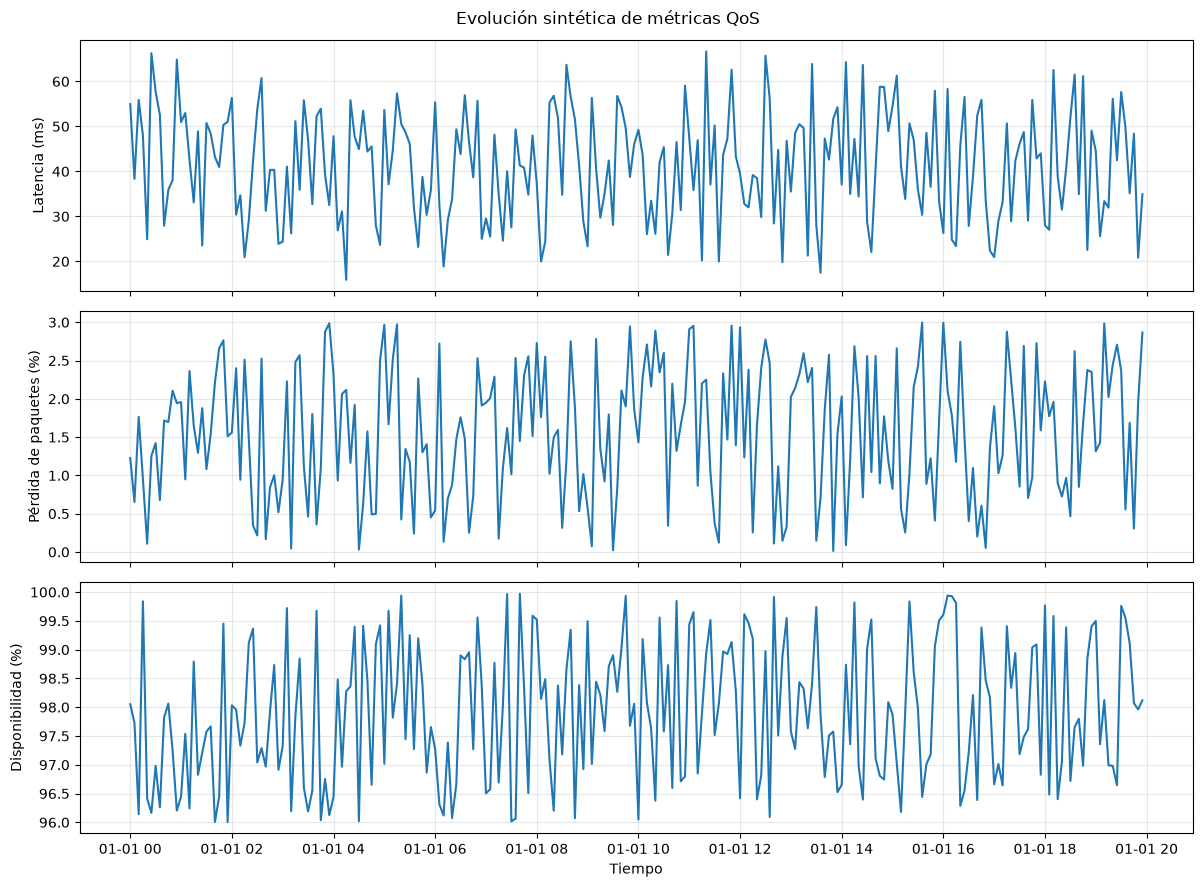

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, column, label in zip(
    axes,
    qos_columns,
    ["Latencia (ms)", "Pérdida de paquetes (%)", "Disponibilidad (%)"]
):
    ax.plot(clean_df["timestamp"], clean_df[column])
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Tiempo")
fig.suptitle("Evolución sintética de métricas QoS")
plt.tight_layout()
plt.show()


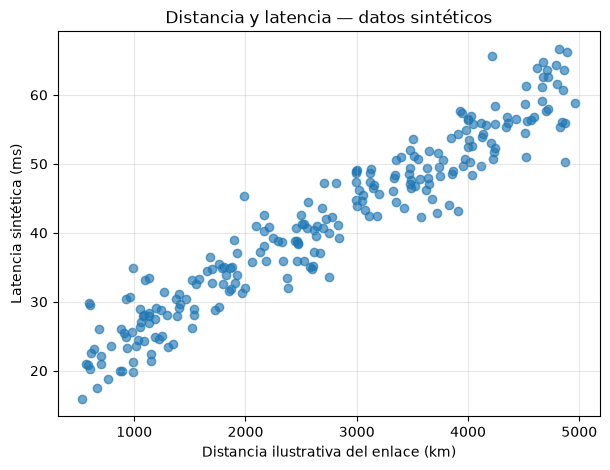

In [21]:
plt.figure(figsize=(7, 5))
plt.scatter(clean_df["distance_km"], clean_df["latency_ms"], alpha=0.65)
plt.xlabel("Distancia ilustrativa del enlace (km)")
plt.ylabel("Latencia sintética (ms)")
plt.title("Distancia y latencia — datos sintéticos")
plt.grid(True, alpha=0.3)
plt.show()


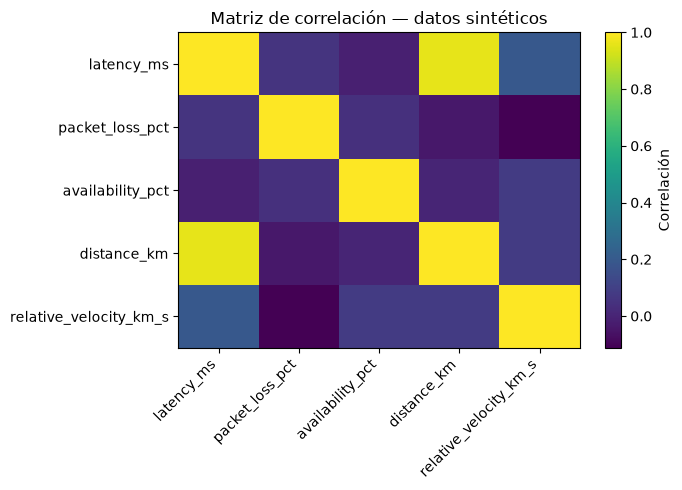

,latency_ms,packet_loss_pct,availability_pct,distance_km,relative_velocity_km_s
latency_ms,1.000,0.055,-0.015,0.958,0.194
packet_loss_pct,0.055,1.000,0.044,-0.039,-0.112
availability_pct,-0.015,0.044,1.000,0.002,0.083
distance_km,0.958,-0.039,0.002,1.000,0.080
relative_velocity_km_s,0.194,-0.112,0.083,0.080,1.000


In [22]:
correlation = clean_df[numeric_columns].corr()

plt.figure(figsize=(7, 5))
plt.imshow(correlation, aspect="auto")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.colorbar(label="Correlación")
plt.title("Matriz de correlación — datos sintéticos")
plt.tight_layout()
plt.show()

display(correlation.round(3))


## 6. Preparación de variables y partición temporal

La tarea se plantea como una regresión temporal: estimar latencia a partir de características del enlace. La partición conserva el orden cronológico para evitar que observaciones futuras se filtren al entrenamiento.


In [23]:
FEATURES = [
    "packet_loss_pct",
    "availability_pct",
    "distance_km",
    "relative_velocity_km_s"
]
TARGET = "latency_ms"

split_index = int(len(clean_df) * 0.80)
train_df = clean_df.iloc[:split_index].copy()
test_df = clean_df.iloc[split_index:].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Último instante de entrenamiento:", train_df["timestamp"].max())
print("Primer instante de prueba:", test_df["timestamp"].min())


Entrenamiento: (192, 4)
Prueba: (48, 4)
Último instante de entrenamiento: 2026-01-01 15:55:00
Primer instante de prueba: 2026-01-01 16:00:00


## 7. Modelo de referencia: regresión bayesiana

Se utiliza `BayesianRidge` como línea base interpretable. El escalado se ajusta únicamente con los datos de entrenamiento. El modelo estima latencia y devuelve una desviación estándar predictiva.


In [24]:
bayesian_model = make_pipeline(
    StandardScaler(),
    BayesianRidge()
)

bayesian_model.fit(X_train, y_train)

predictions, predictive_std = bayesian_model.predict(
    X_test,
    return_std=True
)

print("Modelo ajustado. Predicciones generadas:", len(predictions))


Modelo ajustado. Predicciones generadas: 48


## 8. Evaluación del modelo

Se calculan MAE, RMSE y R² sobre el bloque temporal de prueba. Estas métricas describen únicamente el comportamiento del modelo sobre los datos sintéticos de este ejercicio.


In [25]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

metrics = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Valor": [mae, rmse, r2]
})

display(metrics.round(4))


,Métrica,Valor
0,MAE,2.4336
1,RMSE,3.2129
2,R²,0.9329


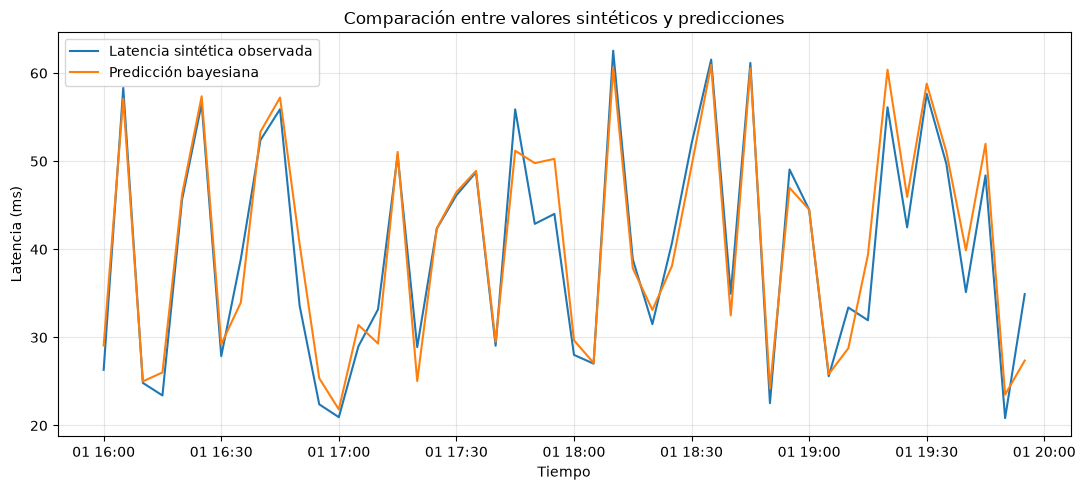

In [26]:
plt.figure(figsize=(11, 5))
plt.plot(test_df["timestamp"], y_test.to_numpy(), label="Latencia sintética observada")
plt.plot(test_df["timestamp"], predictions, label="Predicción bayesiana")
plt.xlabel("Tiempo")
plt.ylabel("Latencia (ms)")
plt.title("Comparación entre valores sintéticos y predicciones")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Incertidumbre predictiva

La desviación estándar predictiva permite construir una banda aproximada bajo el supuesto de una distribución normal. La banda es ilustrativa y no sustituye una evaluación formal de calibración.


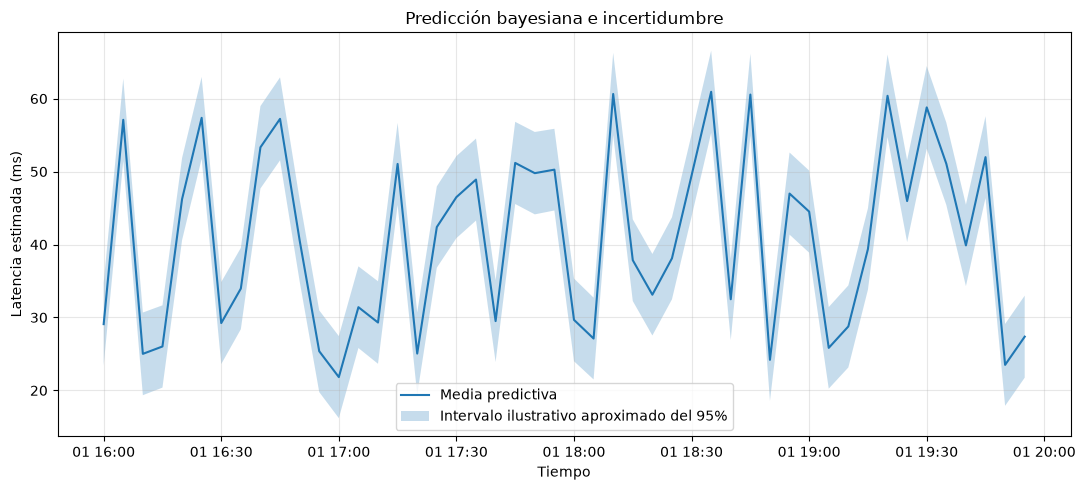

In [27]:
lower = predictions - 1.96 * predictive_std
upper = predictions + 1.96 * predictive_std

plt.figure(figsize=(11, 5))
plt.plot(test_df["timestamp"], predictions, label="Media predictiva")
plt.fill_between(
    test_df["timestamp"],
    lower,
    upper,
    alpha=0.25,
    label="Intervalo ilustrativo aproximado del 95%"
)
plt.xlabel("Tiempo")
plt.ylabel("Latencia estimada (ms)")
plt.title("Predicción bayesiana e incertidumbre")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Exportación de resultados

Se genera un archivo CSV con los valores sintéticos de prueba, las predicciones y los límites ilustrativos del intervalo.


In [28]:
results = pd.DataFrame({
    "timestamp": test_df["timestamp"].to_numpy(),
    "latency_synthetic_ms": y_test.to_numpy(),
    "latency_predicted_ms": predictions,
    "predictive_std_ms": predictive_std,
    "lower_approx_95_ms": lower,
    "upper_approx_95_ms": upper
})

results.to_csv("orbitalroute_ai_predicciones_sinteticas.csv", index=False)
display(results.head(10))
print("Archivo exportado: orbitalroute_ai_predicciones_sinteticas.csv")


,timestamp,latency_synthetic_ms,latency_predicted_ms,predictive_std_ms,lower_approx_95_ms,upper_approx_95_ms
0,2026-01-01 16:00:00,26.316714,29.082713,2.890796,23.416752,34.748674
1,2026-01-01 16:05:00,58.328114,57.096214,2.879275,51.452835,62.739593
2,2026-01-01 16:10:00,24.834160,25.007692,2.890824,19.341677,30.673706
3,2026-01-01 16:15:00,23.410752,26.020222,2.878190,20.378969,31.661474
4,2026-01-01 16:20:00,45.626682,46.217040,2.874305,40.583402,51.850679
5,2026-01-01 16:25:00,56.541145,57.363967,2.859612,51.759127,62.968807
6,2026-01-01 16:30:00,27.874541,29.229345,2.868014,23.608039,34.850652
7,2026-01-01 16:35:00,38.914580,33.963058,2.845137,28.386591,39.539526
8,2026-01-01 16:40:00,52.395348,53.325766,2.881311,47.678397,58.973135
9,2026-01-01 16:45:00,55.907856,57.225371,2.901020,51.539372,62.911369


Archivo exportado: orbitalroute_ai_predicciones_sinteticas.csv


## 11. Alcances, limitaciones y trabajo futuro

Este notebook implementa una demostración reproducible de:
- generación de datos sintéticos;
- revisión, limpieza y descripción de datos;
- visualización exploratoria;
- partición cronológica;
- regresión bayesiana de referencia;
- evaluación básica e intervalos predictivos ilustrativos.

**No implementa ni valida todavía:**
- descarga y versionado de TLE desde CelesTrak/NORAD;
- propagación orbital mediante SGP4;
- construcción del grafo dinámico de conectividad;
- entrenamiento y comparación de una red LSTM;
- aprendizaje por refuerzo para selección de rutas;
- validación con mediciones QoS reales.

Para convertir esta demostración en un experimento del proyecto, se deberá sustituir el conjunto sintético por datos reales o simulados con trazabilidad, documentar su procedencia y repetir la evaluación con un protocolo temporal reproducible.

### Conclusión

El notebook muestra cómo organizar un flujo inicial de análisis y predicción de latencia para OrbitalRoute AI. Los resultados son exclusivamente didácticos; no demuestran una mejora de QoS ni el funcionamiento operativo de una constelación LEO.
